# feature engineering list:

1. Keywords jackpot
2. Self-reference jackpot

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/mini_project_1_data.csv")

import numpy as np

df["shares"] = np.log1p(df["shares"])

### Engineered Jackpot Features — Mathematical Formulas

#### 1. Jackpot Ratio

Measures how much more popular the strongest keyword or referenced article is relative to the average.

$$
\text{Jackpot Ratio} = \frac{\text{Maximum}}{\text{Average}}
$$

#### 2. Jackpot Premium

Measures the absolute popularity advantage of the strongest keyword or referenced article over the average, with a logarithmic transformation to reduce skewness.

$$
\text{Jackpot Premium} = \ln(1 + \text{Maximum} - \text{Average})
$$

#### 3. Jackpot Dominance

Measures how far the average lies below the maximum relative to the overall popularity range.

$$
\text{Jackpot Dominance} = \frac{\text{Maximum} - \text{Average}}{\text{Maximum} - \text{Minimum}}
$$

## Keyword Jackpot Features — Hypotheses

| Feature | Hypothesis |
|---|---|
| `keyword_jackpot_ratio` | Does having a keyword substantially more popular than the average keyword correspond to higher article shares? |
| `keyword_jackpot_premium` | Does the absolute popularity gap between the most popular keyword and the average keyword correspond to higher article shares? |
| `keyword_jackpot_dominance` | Does having one exceptionally popular keyword, rather than consistently popular keywords, correspond to higher article shares? |


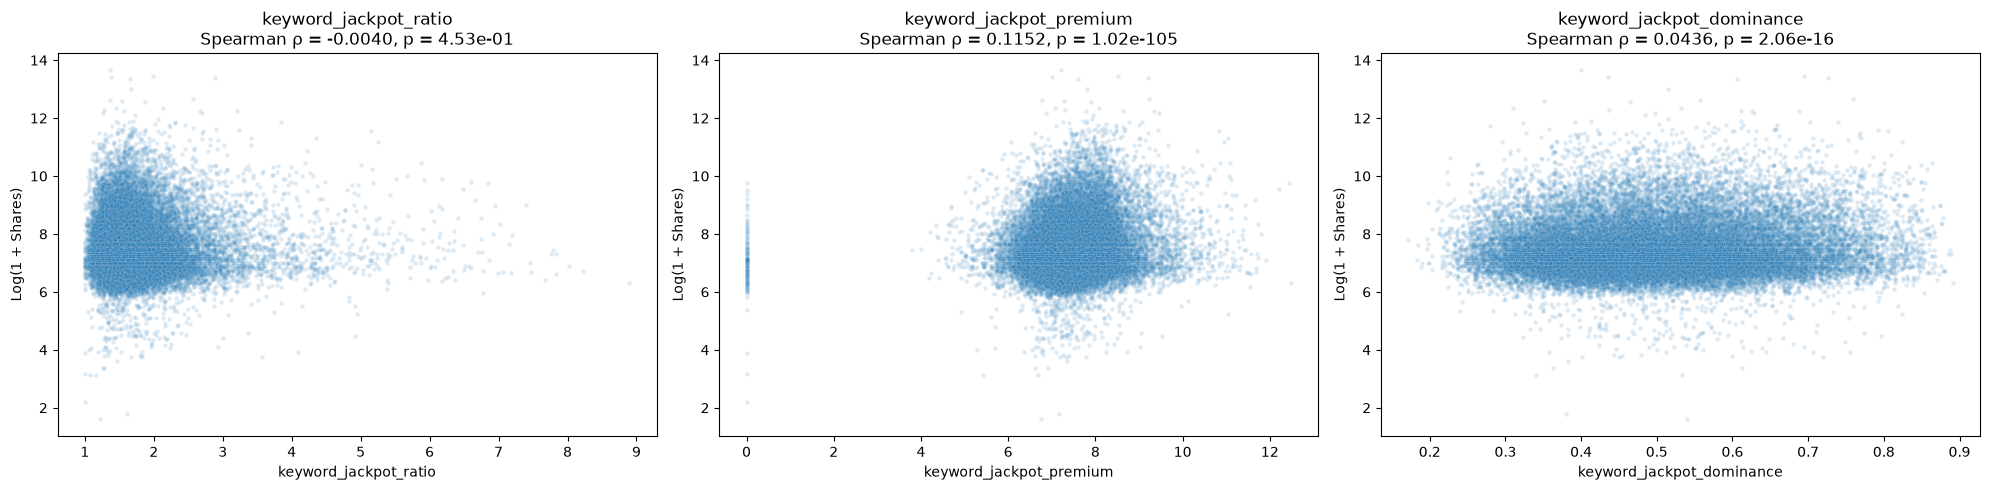

,feature,spearman_rho,p_value
0,keyword_jackpot_ratio,-0.00398,0.45281
1,keyword_jackpot_premium,0.11523,0.00000
2,keyword_jackpot_dominance,0.04357,0.00000


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# 1. Engineer jackpot features
df["keyword_jackpot_ratio"] = (
    df["kw_max_avg"] /
    df["kw_avg_avg"].replace(0, np.nan)
)

df["keyword_jackpot_premium"] = np.log1p(
    df["kw_max_avg"] - df["kw_avg_avg"]
)

df["keyword_jackpot_dominance"] = (
    (df["kw_max_avg"] - df["kw_avg_avg"]) /
    (df["kw_max_avg"] - df["kw_min_avg"]).replace(0, np.nan)
)

# 2. Plot against log-shares
features = [
    "keyword_jackpot_ratio",
    "keyword_jackpot_premium",
    "keyword_jackpot_dominance"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

results = []

for ax, feature in zip(axes, features):

    subset = (
        df[[feature, "shares"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    rho, p = spearmanr(subset[feature], subset["shares"])

    results.append({
        "feature": feature,
        "spearman_rho": rho,
        "p_value": p
    })

    sns.scatterplot(
        data=subset,
        x=feature,
        y="shares",
        alpha=0.15,
        s=10,
        ax=ax
    )

    ax.set_title(f"{feature}\nSpearman ρ = {rho:.4f}, p = {p:.2e}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Log(1 + Shares)")

plt.tight_layout()
plt.show()

# 3. Display correlation results
results_df = pd.DataFrame(results)

display(results_df.round(5))

### Statistical Interpretation of Engineered Keyword Features

**1. Jackpot Ratio — No statistically significant monotonic association (ρ = −0.0040, p = 0.453)**

The correlation is effectively zero, with a p-value exceeding 0.05. This provides no statistically significant evidence that the relative popularity of an article's strongest keyword, compared with its average keyword popularity, is monotonically associated with article shares.

**2. Jackpot Premium — Weak positive association (ρ = 0.1152, p ≈ 1.02 × 10⁻¹⁰⁵)**

The jackpot premium exhibits the strongest positive association with shares among the three engineered features. Articles with a larger absolute difference between their most popular keyword and average keyword popularity tend to receive slightly more shares.

However, the correlation remains weak, suggesting that the magnitude of this popularity gap alone has limited explanatory value.

**3. Jackpot Dominance — Negligible positive association (ρ = 0.0436, p ≈ 2.06 × 10⁻¹⁶)**

Although statistically significant, the correlation is negligible in magnitude. This suggests that the relative dominance of an article's strongest keyword within its overall keyword popularity range has little monotonic association with shares.

Given the dataset's large sample size (approximately 40,000 observations), even very small associations can produce extremely low p-values.

### Comparison with Original Keyword Features

The original kw_avg_avg feature exhibits a substantially stronger positive correlation with shares (ρ = 0.2547) than any of the engineered jackpot features.

This suggests that overall historical keyword popularity may be more informative than the presence of a single exceptionally popular keyword when considering the general relationship with article shares.

However, these findings do not necessarily invalidate the original jackpot hypothesis. Spearman correlation measures overall monotonic association and may fail to capture relationships concentrated in the upper tail of the share distribution.

In particular, a highly popular keyword might have little influence on typical articles while still increasing the likelihood of exceptionally high engagement.

## Self-Reference Jackpot Features — Hypotheses

| Feature | Hypothesis |
|---|---|
| `self_reference_jackpot_ratio` | Does referencing an article substantially more popular than the average referenced article correspond to higher shares? |
| `self_reference_jackpot_premium` | Does the absolute popularity gap between the most popular referenced article and the average referenced article correspond to higher shares? |
| `self_reference_jackpot_dominance` | Does referencing one exceptionally popular article, rather than consistently popular referenced articles, correspond to higher shares? |

In [5]:
import numpy as np

df["self_reference_jackpot_ratio"] = (
    df["self_reference_max_shares"] /
    df["self_reference_avg_shares"].replace(0, np.nan)
)

df["self_reference_jackpot_premium"] = np.log1p(
    df["self_reference_max_shares"] - df["self_reference_avg_shares"]
)

df["self_reference_jackpot_dominance"] = (
    (df["self_reference_max_shares"] - df["self_reference_avg_shares"]) /
    (
        df["self_reference_max_shares"] -
        df["self_reference_min_shares"]
    ).replace(0, np.nan)
)

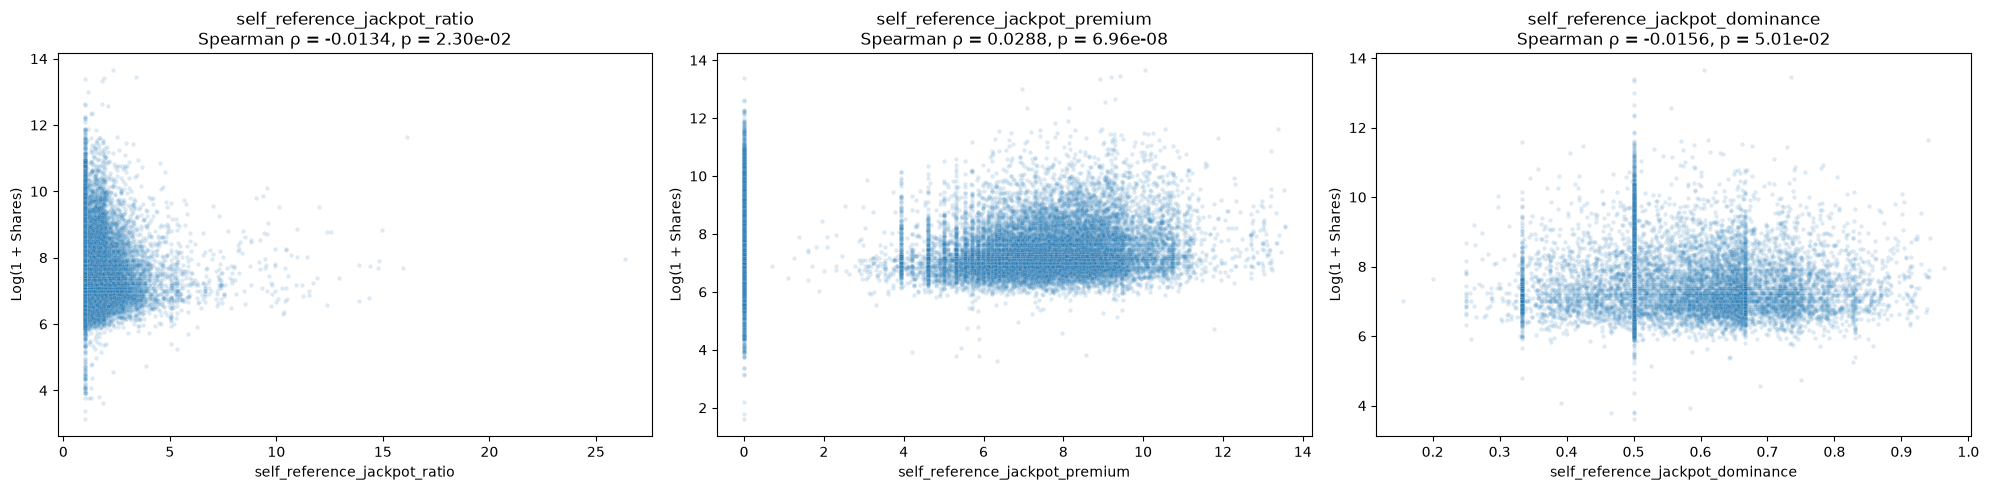

,feature,n,spearman_rho,p_value
0,self_reference_jackpot_ratio,28624,-0.013438,2.299099e-02
1,self_reference_jackpot_premium,34959,0.028834,6.959993e-08
2,self_reference_jackpot_dominance,15797,-0.015587,5.010282e-02


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import pandas as pd

features = [
    "self_reference_jackpot_ratio",
    "self_reference_jackpot_premium",
    "self_reference_jackpot_dominance"
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
results = []

for ax, feature in zip(axes, features):
    subset = (
        df[[feature, "shares"]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    rho, p = spearmanr(subset[feature], subset["shares"])

    results.append({
        "feature": feature,
        "n": len(subset),
        "spearman_rho": rho,
        "p_value": p
    })

    sns.scatterplot(
        data=subset,
        x=feature,
        y="shares",
        alpha=0.15,
        s=10,
        ax=ax
    )

    ax.set_title(f"{feature}\nSpearman ρ = {rho:.4f}, p = {p:.2e}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Log(1 + Shares)")

plt.tight_layout()
plt.show()

display(pd.DataFrame(results))

In [7]:
import numpy as np
import pandas as pd

original_features = [
    "self_reference_min_shares",
    "self_reference_max_shares",
    "self_reference_avg_shares"
]

engineered_features = [
    "self_reference_jackpot_ratio",
    "self_reference_jackpot_premium",
    "self_reference_jackpot_dominance"
]

summary = pd.DataFrame({
    "zeros": (df[original_features + engineered_features] == 0).sum(),
    "NaNs": df[original_features + engineered_features].isna().sum(),
    "infinities": np.isinf(df[original_features + engineered_features]).sum()
})

summary["zero_pct"] = (
    summary["zeros"] / len(df) * 100
).round(2)

display(summary)

,zeros,NaNs,infinities,zero_pct
self_reference_min_shares,6335,721,0,17.76
self_reference_max_shares,6335,721,0,17.76
self_reference_avg_shares,6335,721,0,17.76
self_reference_jackpot_ratio,0,7056,0,0.00
self_reference_jackpot_premium,19162,721,0,53.71
self_reference_jackpot_dominance,0,19883,0,0.00
